# Autotune
Autotune **adjusts and corrects the pitch of recorded voices and instruments** (*How Does AutoTune Work? The Science Behind Pitch Correction*, n.d.).

It does this by detecting the pitch of an incoming signal, then compares the detected pitch to a predefined scale or tone, if the incoming pitch falls outside of the desired value autotune shifts the pitch to the nearest value in the scale (*How Does AutoTune Work? The Science Behind Pitch Correction*, n.d.).

You can also adjust the speed at which autotune retunes the music:
*  **faster** = **more robotic sound**, autotune is very noticeable
*  **slower** = more natural sound

(*How Does AutoTune Work? The Science Behind Pitch Correction*, n.d.)

We can create a simple auto-tuner consisting of mono-phonic pitch detection followed by pitch shifting to conform to a paticular scale (MIR book).

### References:
*  *How does AutoTune work? The science behind pitch correction.* (n.d.). AutoTune. https://www.antarestech.com/blog/the-science-behind-auto-tune?srsltid=AYCX9vKiRnSOQeDIUF0_00O7EB8DCJ6QT-bus7lAQDN1mPHl-V7_l1RC
*  MIR book: exploring autotuning https://github.com/gtzan/mir_book/blob/master/old_notebooks/exploring_autotuning.ipynb




In [3]:
pip install demucs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.1/18.1 MB 92.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [demucs]


In [4]:
pip install psola

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 29.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [psola]


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as signal
import IPython.display as ipd
import librosa
import scipy.io.wavfile as wav
from scipy.io.wavfile import write
import psola
import scipy.signal as sig
import demucs.separate

# use this filename when working locally
filename = '/content/tomsdiner_mono.wav'
# use this filename when working within github
# filename = '../../data/tomsdiner_mono.wav'
srate, tomsdiner = wav.read(filename)

# Using Demucs, a source-separation model that can split a recording into vocals
# and instrumental accompaniment so that we can apply autotune to only the vocals

# in colab: creates two files: vocals.wav and no_vocals.wav
demucs.separate.main([
    "--two-stems=vocals",
    "-n", "htdemucs_ft",
    "-o", "/content",
    "/content/tomsdiner_stereo.wav"
])
# load the isolated vocals into librosa
vocals, srate = librosa.load(
    "/content/htdemucs_ft/tomsdiner_stereo/vocals.wav",
    sr=None,
    mono=True
)

instrumental, _ = librosa.load(
    "/content/htdemucs_ft/tomsdiner_stereo/no_vocals.wav",
    sr=srate,
    mono=True
)

# in github: creates two files: vocals.wav and no_vocals.wav
# demucs.separate.main([
#     "--two-stems=vocals",
#     "-n", "htdemucs_ft",
#     "-o", ".",
#     "../../data/tomsdiner_stereo.wav"
# ])

# # load the isolated vocals into librosa
# vocals, srate = librosa.load(
#     "./htdemucs_ft/tomsdiner_stereo/vocals.wav",
#     sr=None,
#     mono=True
# )

# instrumental, _ = librosa.load(
#     "./htdemucs_ft/tomsdiner_stereo/no_vocals.wav",
#     sr=srate,
#     mono=True
# )

htdemucs_ft.yaml:   0%|          | 0.00/149 [00:00<?, ?B/s]

f7e0c4bc.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

f7e0c4bc.safetensors: downloading bytes:           |  0.00B            

d12395a8.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

d12395a8.safetensors: downloading bytes:           |  0.00B            

92cfc3b6.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

92cfc3b6.safetensors: downloading bytes:           |  0.00B            

04573f0d.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

04573f0d.safetensors: downloading bytes:           |  0.00B            

Selected model is a bag of 4 models. You will see that many progress bars per track.
Separated tracks will be stored in /content/htdemucs_ft
Separating track /content/tomsdiner_stereo.wav


100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:09<00:00,  1.55s/seconds]
100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:08<00:00,  1.40s/seconds]
100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:06<00:00,  1.08s/seconds]
100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:06<00:00,  1.14s/seconds]


In [8]:
def save_audio_to_wav(filename, audio, srate=44100):
  """Saves an audio array as a wav file"""
  audio = audio / np.max(np.abs(audio))
  write(filename, srate, audio.astype(np.float32))


In [6]:
# listen to the original audio, then the isolated vocals to double check they sound right

# original unseparated audio
ipd.Audio(tomsdiner, rate=srate)


In [31]:
# vocals separated from audio
ipd.display(ipd.Audio(vocals, rate=srate))
save_audio_to_wav('audios/tomsdiner_vocals_original.wav', vocals, srate)

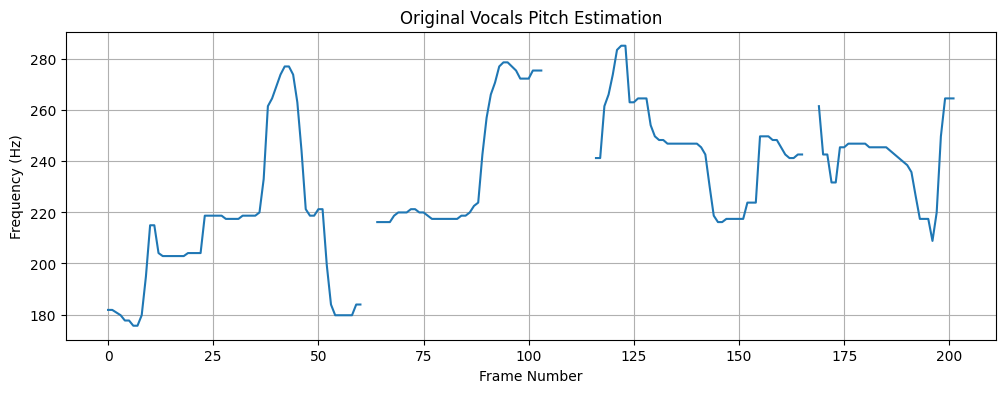

In [10]:
# We can extract the pitch contour using the pyin fundamental frequency estimator from librosa

hopSize = 1024 # How many samples we move forward before analyzing the next frame
winSize = 4096 # How many audio samples are analyzed at once


# Monophonic pitch extraction using librosa.pyin: try with C3-C6 and C4-C6
f0, voiced_flag, voiced_probs = librosa.pyin(
  vocals,
  sr=srate,
  frame_length=winSize,
  hop_length=hopSize,
  fmin=librosa.note_to_hz('C2'),
  fmax=librosa.note_to_hz('C6'),
  center=False
)

# Apply a median filter to the estimated pitch track to remove sudden isolated errors in pitch estimation
f0 = signal.medfilt(f0, kernel_size=3)

# Plot Frequency to Frame Number
plt.figure(figsize=(12, 4))
plt.plot(f0)
plt.xlabel("Frame Number")
plt.ylabel("Frequency (Hz)")
plt.title("Original Vocals Pitch Estimation")
plt.grid()
plt.savefig('plots/pitch_estimation_tomsdiner_original_vocals')
plt.show()


offsets = np.arange(0, len(vocals)-winSize, hopSize)

# Define some target scales to try out

# 1. Single note - forces all pitches to 70
single = np.array([79.0])

# 2. Low register
low_scale = np.array([48, 52, 55])

# 3. Middle register
middle_scale = np.array([57, 60, 64])

# 4. High register
high_scale = np.array([67, 71, 74])

# 5. Very high register
extreme_scale = np.array([72, 76, 79])



In [24]:
# Find the closest target pitch
def closest(m, scale):
    return scale[np.argmin(np.abs(scale-m))]

# Basic autotune function: maps each pitch to target pitch and does pitch shifting without time stretching
def autotune(audio_signal, scale):
    output = np.zeros(len(audio_signal))
    for (m,o) in enumerate(offsets):
        mf0 = librosa.hz_to_midi(f0[m])
        frame = audio_signal[o:o+winSize]
        window = signal.windows.hann(len(frame))
        if not(np.isnan(mf0)):
            steps = mf0 - closest(mf0,scale)
            frame = librosa.effects.pitch_shift(frame, sr = srate, n_steps = -steps)
        frame = window * frame
        output[o:o+winSize] += frame
    return output

# PSOLA is the pitch modification method most associated with the "autotune" sound.
def autotune_psola(audio_signal, scale):
    fmin = librosa.note_to_hz('C2')
    fmax = librosa.note_to_hz('C7')
    mf0 = librosa.hz_to_midi(f0)
    corrected_f0 = [librosa.midi_to_hz(closest(mf, scale)) for mf in mf0]
    med_filtered = sig.medfilt(corrected_f0, kernel_size=3)
    output = psola.vocode(audio_signal, sample_rate=int(srate), target_pitch=med_filtered, fmin=fmin, fmax=fmax)
    return output

def autotune_and_mix(vocals, instrumental, scale, autotune_func):
    # Autotune the vocals using the chosen function and scale
    autotuned_vocals = autotune_func(vocals, scale)

    # Ensure both audio signals have the same length
    length = min(len(autotuned_vocals), len(instrumental))

    # Combine autotuned vocals with original instrumental
    final_audio = (
        autotuned_vocals[:length] +
        instrumental[:length]
    )

    # Prevent clipping
    peak = np.max(np.abs(final_audio))
    if peak > 1:
        final_audio = final_audio / peak

    return final_audio

single_output_vocals = autotune(vocals, single)
single_output_audio = autotune_and_mix(vocals, instrumental, single, autotune)

single_output_psola_vocals = autotune_psola(vocals, single)
single_output_psola_audio = autotune_and_mix(vocals, instrumental, single, autotune_psola)

low_scale_output_vocals = autotune(vocals, low_scale)
low_scale_output_audio = autotune_and_mix(vocals, instrumental, low_scale, autotune)

low_scale_output_psola_vocals = autotune_psola(vocals, low_scale)
low_scale_output_psola_audio = autotune_and_mix(vocals, instrumental, low_scale, autotune_psola)

middle_scale_output_vocals = autotune(vocals, middle_scale)
middle_scale_output_audio = autotune_and_mix(vocals, instrumental, middle_scale, autotune)

middle_scale_output_psola_vocals = autotune_psola(vocals, middle_scale)
middle_scale_output_psola_audio = autotune_and_mix(vocals, instrumental, middle_scale, autotune_psola)

high_scale_output_vocals = autotune(vocals, high_scale)
high_scale_output_audio = autotune_and_mix(vocals, instrumental, high_scale, autotune)

high_scale_output_psola_vocals = autotune_psola(vocals, high_scale)
high_scale_output_psola_audio = autotune_and_mix(vocals, instrumental, high_scale, autotune_psola)

extreme_scale_output_audio = autotune_and_mix(vocals, instrumental, extreme_scale, autotune)
extreme_scale_output_psola_audio = autotune_and_mix(vocals, instrumental, extreme_scale, autotune_psola)

Single Scale Output:
- autotune just vocals
- autotune full audio
- psola autotune just vocals
- psola autotune full audio

In [32]:
ipd.Audio(single_output_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_single.wav', single_output_vocals, srate)

In [33]:
ipd.Audio(single_output_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_single.wav', single_output_audio, srate)

In [34]:
ipd.Audio(single_output_psola_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_psola_single.wav', single_output_psola_vocals, srate)

In [35]:
ipd.Audio(single_output_psola_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_psola_single.wav', single_output_psola_audio, srate)

Low Scale
- autotune just vocals
- autotune audio
- psola autotune just vocals
- psola autotune audio


In [36]:
ipd.Audio(low_scale_output_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_low.wav', low_scale_output_vocals, srate)

In [37]:
ipd.Audio(low_scale_output_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_low.wav', low_scale_output_audio, srate)

In [38]:
ipd.Audio(low_scale_output_psola_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_psola_low.wav', low_scale_output_psola_vocals, srate)

In [39]:
ipd.Audio(low_scale_output_psola_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_psola_low.wav', low_scale_output_psola_audio, srate)

Middle Scale
- autotune just vocals
- autotune audio
- psola autotune just vocals
- psola autotune audio

In [40]:
ipd.Audio(middle_scale_output_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_middle.wav', middle_scale_output_vocals, srate)

In [41]:
ipd.Audio(middle_scale_output_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_middle.wav', middle_scale_output_audio, srate)

In [42]:
ipd.Audio(middle_scale_output_psola_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_psola_middle.wav', middle_scale_output_psola_vocals, srate)

In [43]:
ipd.Audio(middle_scale_output_psola_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_psola_middle.wav', middle_scale_output_psola_audio, srate)

High Scale
- autotune just vocals
- autotune audio
- psola autotune just vocals
- psola autotune audio

In [44]:
ipd.Audio(high_scale_output_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_high.wav', high_scale_output_vocals, srate)

In [45]:
ipd.Audio(high_scale_output_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_high.wav', high_scale_output_audio, srate)

In [46]:
ipd.Audio(high_scale_output_psola_vocals, rate=srate)
save_audio_to_wav('audios/tomsdiner_vocals_psola_high.wav', high_scale_output_psola_vocals, srate)

In [47]:
ipd.Audio(high_scale_output_psola_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_psola_high.wav', high_scale_output_psola_audio, srate)

Extreme Scale
- autotune audio
- psola autotune audio


In [48]:
ipd.Audio(extreme_scale_output_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_extreme.wav', extreme_scale_output_audio, srate)

In [49]:
ipd.Audio(extreme_scale_output_psola_audio, rate=srate)
save_audio_to_wav('audios/tomsdiner_audio_psola_extreme.wav', extreme_scale_output_psola_audio, srate)

# Plots

The first three plots will compare the original vocals, basic autotune, and PSOLA autotune. Each plot will show the target scale notes as dashed lines.

Notice how the autotuned vocals conform to the scale notes and don't move as naturally as the original audio.

We can also see that for the lower and higher scales, most of the notes end up being the same as their closest note to the original notes are usually the highest or lowest in the scale.

The basic autotune (in orange) produces a relatively stable pitch contour near the target scale notes while the PSOLA (green) contains more abrupt deviations in certain sections (especially the low scale). However in the high scale the PSOLA pitch contour follows the target notes more closely. The spikes and deviations are probably due to inacurate pitch estimates so it's hard to determine which autotune method is more accurate based on these plots alone.

Based on the audio, PSOLA audio sounds more robotic and less real, while the autotuned audio sounds much more natural and close to the orignal sound.




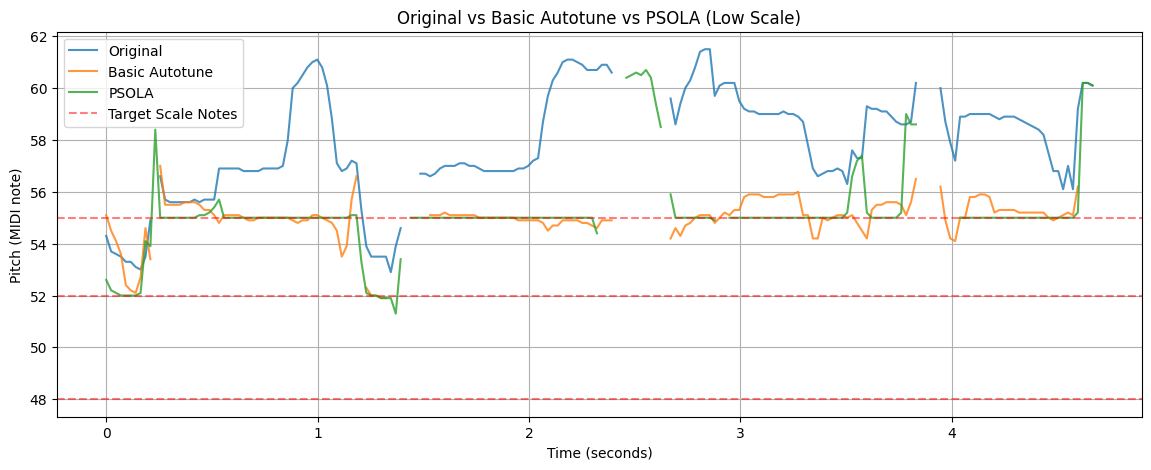

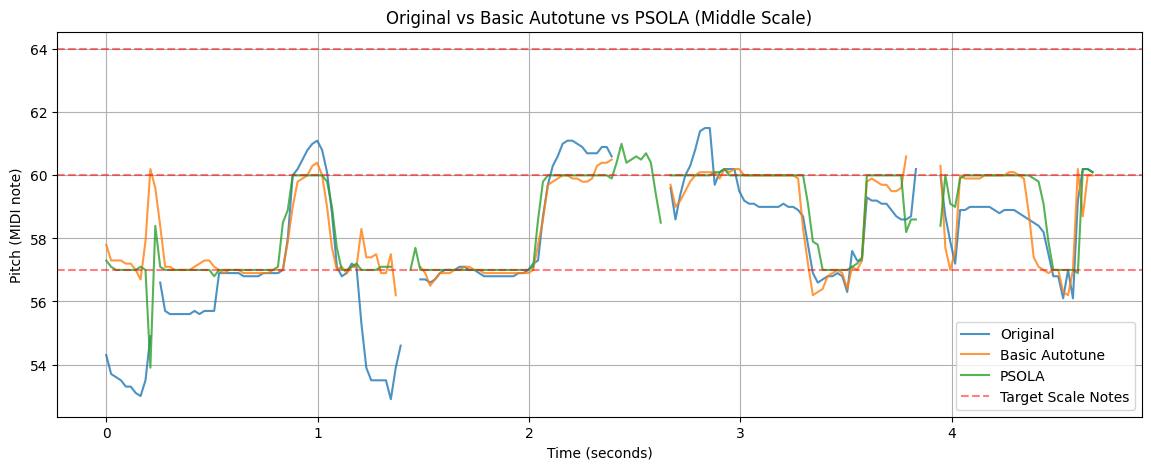

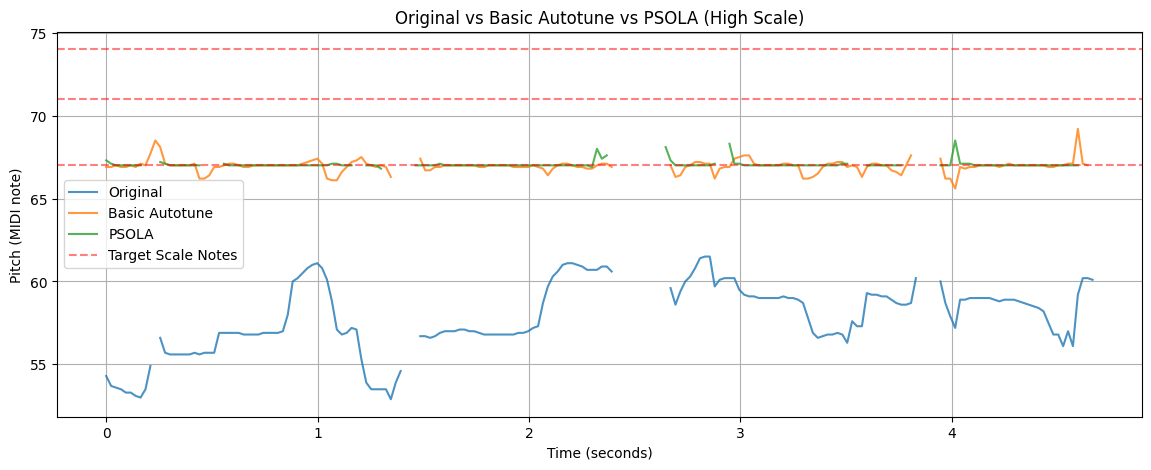

In [30]:
# Define scales and corresponding vocal outputs
scales = {
    "low": (low_scale, low_scale_output_vocals, low_scale_output_psola_vocals),
    "middle": (middle_scale, middle_scale_output_vocals, middle_scale_output_psola_vocals),
    "high": (high_scale, high_scale_output_vocals, high_scale_output_psola_vocals)
}

# Plot settings
start_time = 0
end_time = 4.8

start = int(start_time * srate)
end = int(end_time * srate)

# Generate one plot for each scale
for scale_name, (scale, autotune_audio, psola_audio) in scales.items():

    signals = {
        "Original": vocals,
        "Basic Autotune": autotune_audio,
        "PSOLA": psola_audio
    }

    plt.figure(figsize=(14, 5))

    for label, audio in signals.items():
        # Estimate fundamental frequency
        estimated_f0, _, _ = librosa.pyin(
            audio[start:end],
            sr=srate,
            frame_length=winSize,
            hop_length=hopSize,
            fmin=librosa.note_to_hz("C2"),
            fmax=librosa.note_to_hz("C7"),
            center=False
        )

        # Convert frequency to MIDI notes
        midi_pitch = librosa.hz_to_midi(estimated_f0)
        times = start_time + np.arange(len(midi_pitch)) * hopSize / srate

        plt.plot(times, midi_pitch, label=label, alpha=0.8)

    # Plot target scale notes as horizontal dashed lines
    for i, note in enumerate(scale):
        plt.axhline(
            note,
            color="red",
            linestyle="--",
            alpha=0.5,
            label="Target Scale Notes" if i == 0 else None
        )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Pitch (MIDI note)")
    plt.title(f"Original vs Basic Autotune vs PSOLA ({scale_name.capitalize()} Scale)")
    plt.legend()
    plt.grid()

    # Save plot as PNG
    plt.savefig(f"plots/{scale_name}_scale_comparison.png",
                dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()